
# Offline filtering of a simulated 1D trajectory

The code below performs offline Kalman filtering of a simulated 1D trajectory.


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joacorapela/lds_itba_2026/blob/main/code/notebooks/solutions/plotBatchFilterSimulated1DTrajectoryDWPA.ipynb)

## Import packages



In [1]:
import numpy as np
import plotly.graph_objects as go

## Set initial conditions and parameters



In [2]:
pos_x0 = 0.0
vel_x0 = 0.0
ace_x0 = 0.0
dt = 1e-3
num_pos = 1000
sigma_a = 1.0
sigma_measurement = 1.0
sqrt_diag_V0_value = 1e-03

## Set LDS parameters



In [3]:
B = np.array([[1, dt, .5*dt**2],
              [0, 1, dt],
              [0, 0, 1]],
             dtype=np.double)
Z = np.array([[1, 0, 0]], dtype=np.double)

Q = sigma_a**2 * np.array([[dt**4/4, dt**3/2, dt**2/2],
                           [dt**3/2, dt**2,   dt],
                           [dt**2/2, dt,      1]],
                          dtype=np.double)
R = np.diag([sigma_measurement**2])
m0 = np.array([pos_x0, vel_x0, ace_x0],
              dtype=np.double)
V0 = np.diag(np.ones(len(m0))*sqrt_diag_V0_value**2)

m0 = np.array([pos_x0, vel_x0, ace_x0],
              dtype=np.double)
V0 = np.diag(np.ones(len(m0))*sqrt_diag_V0_value**2)

## Sample from the LDS



In [4]:
# fix random seed
np.random.seed(seed=1234)

M = B.shape[0]
P = Z.shape[0]

# state noise
w = np.random.multivariate_normal(np.zeros(M), Q, num_pos).T
# measurement noise
v = np.random.multivariate_normal(np.zeros(P), R, num_pos).T
# initial state noise
x0 = np.random.multivariate_normal(m0, V0, 1).flatten()
# sample
x = np.empty(shape=(M, num_pos))
y = np.empty(shape=(P, num_pos))
x[:, 0] = B @ x0 + w[:, 0]
for n in range(1, num_pos):
    x[:, n] = B @ x[:, n-1] + w[:, n]
y = Z @ x + v
t = np.arange(num_pos) * dt

## Estimate velocities and accelerations using finite differences



In [5]:
vel_est_fd = np.diff(y[0, :]) / dt
acc_est_fd = np.diff(vel_est_fd) / dt

## Perform batch filtering



In [6]:
N = y.shape[1]
xnn1 = np.empty(shape=[M, 1, N])
Pnn1 = np.empty(shape=[M, M, N])
xnn = np.empty(shape=[M, 1, N])
Pnn = np.empty(shape=[M, M, N])
innov = np.empty(shape=[P, 1, N])
Sn = np.empty(shape=[P, P, N])
K = np.empty(shape=[M, P, N])

for k in range(N):
    if k == 0:
        xnn1[:, 0, 0] = B @ m0
        Pnn1[:, :, 0] = B @ V0 @ B.T + Q
    else:
        xnn1[:, :, k] = B @ xnn[:, :, k-1]
        Pnn1[:, :, k] = B @ Pnn[:, :, k-1] @ B.T + Q
    Stmp = Z @ Pnn1[:, :, k] @ Z.T + R
    Sn[:, :, k] = (Stmp + Stmp.T) / 2
    Sinv = np.linalg.inv(Sn[:, :, k])
    K[:, :, k] = Pnn1[:, :, k] @ Z.T @ Sinv
    pred_obs = Z @ xnn1[:, :, k]
    innov[:, 0, k] = y[:, k] - pred_obs[:, 0]
    xnn[:, :, k] = ...
    Pnn[:, :, k] = ...

filter_res = {"xnn1": xnn1, "Pnn1": Pnn1, "xnn": xnn, "Pnn": Pnn,
              "innov": innov, "K": K, "Sn": Sn}

## Set variables for plotting



In [7]:
N = y.shape[1]
time = np.arange(0, N*dt, dt)
filtered_means = filter_res["xnn"]
filtered_covs = filter_res["Pnn"]
filter_stds = np.sqrt(np.diagonal(a=filtered_covs, axis1=0, axis2=1))
color_true = "blue"
color_other = "black"
color_filtered_pattern = "rgba(255,0,0,{:f})"
cb_alpha = 0.3

## Define function for plotting



In [8]:
def get_fig_kinematics_vs_time(
        time,
        true_x,
        other_x,
        filtered_mean_x,
        filtered_ci_x_lower,
        filtered_ci_x_upper,
        cb_alpha,
        color_true,
        color_other,
        color_filtered_pattern,
        xlabel, ylabel, other_label):

    fig = go.Figure()
    trace_true_x = go.Scatter(
        x=time, y=true_x,
        mode="markers",
        marker={"color": color_true},
        name="true",
        showlegend=True,
    )
    fig.add_trace(trace_true_x)
    if other_x is not None:
        trace_other = go.Scatter(
            x=time, y=other_x,
            mode="markers",
            marker={"color": color_other},
            name=other_label,
            showlegend=True,
        )
        fig.add_trace(trace_other)
    trace_inf_x = go.Scatter(
        x=time, y=filtered_mean_x,
        mode="markers",
        marker={"color": color_filtered_pattern.format(1.0)},
        name="filtered",
        showlegend=True,
        legendgroup="filtered_x",
    )
    fig.add_trace(trace_inf_x)
    trace_inf_x_cb = go.Scatter(
        x=np.concatenate([time, time[::-1]]),
        y=np.concatenate([filtered_ci_x_upper,
                          filtered_ci_x_lower[::-1]]),
        fill="toself",
        fillcolor=color_filtered_pattern.format(cb_alpha),
        line=dict(color=color_filtered_pattern.format(0.0)),
        showlegend=False,
        legendgroup="filtered_x",
    )
    fig.add_trace(trace_inf_x_cb)

    fig.update_layout(xaxis_title=xlabel,
                      yaxis_title=ylabel,
                      paper_bgcolor='rgba(0,0,0,0)',
                      plot_bgcolor='rgba(0,0,0,0)',
                      # yaxis_range=[filtered_mean_x.min(),
                      #              filtered_mean_x.max()],
                     )
    return fig

## Plot true, measured and filtered positions (with 95% confidence band)



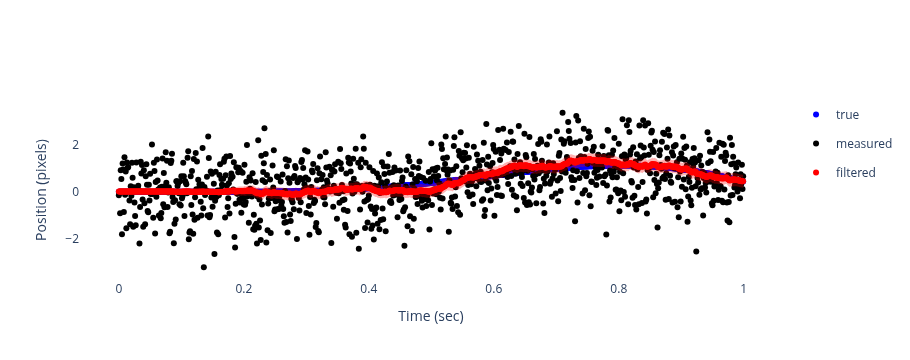

In [9]:
true_x = x[0, :]
other_x = y[0, :]
other_label = "measured"
color_other = "black"
filter_mean_x = filtered_means[0, 0, :]

filter_ci_pos_upper = filter_mean_x + 1.96*filter_stds[:, 0]
filter_ci_pos_lower = filter_mean_x - 1.96*filter_stds[:, 0]

fig = get_fig_kinematics_vs_time(
    time=time,
    true_x=true_x,
    other_x=other_x,
    filtered_mean_x=filter_mean_x,
    filtered_ci_x_upper=filter_ci_pos_upper,
    filtered_ci_x_lower=filter_ci_pos_lower,
    cb_alpha=cb_alpha,
    color_true=color_true,
    color_filtered_pattern=color_filtered_pattern,
    color_other=color_other,
    xlabel="Time (sec)", ylabel="Position (pixels)", other_label=other_label)
fig

## Plot true and filtered velocities (with 95% confidence band)



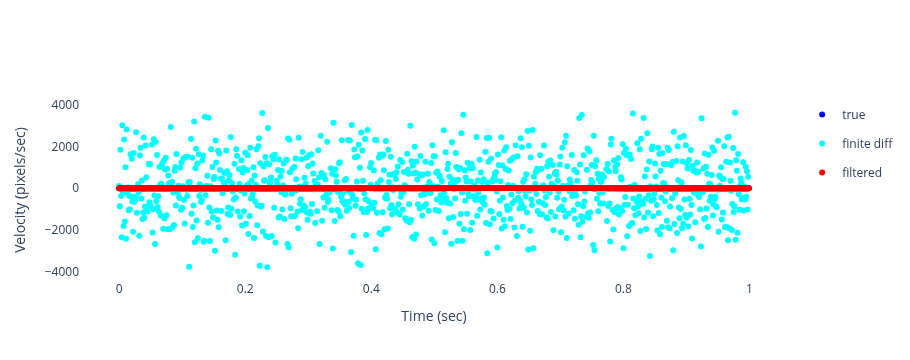

In [10]:
true_x = x[1, :]
other_x = vel_est_fd
other_label = "finite diff"
color_other = "cyan"
filter_mean_x = filtered_means[1, 0, :]

filter_ci_vel_upper = filter_mean_x + 1.96*filter_stds[:, 1]
filter_ci_vel_lower = filter_mean_x - 1.96*filter_stds[:, 1]

fig = get_fig_kinematics_vs_time(
    time=time,
    true_x=true_x,
    other_x=other_x,
    filtered_mean_x=filter_mean_x,
    filtered_ci_x_upper=filter_ci_vel_upper,
    filtered_ci_x_lower=filter_ci_vel_lower,
    cb_alpha=cb_alpha,
    color_true=color_true,
    color_filtered_pattern=color_filtered_pattern,
    color_other=color_other,
    xlabel="Time (sec)", ylabel="Velocity (pixels/sec)",
    other_label=other_label)
fig

## Plot true and filtered accelerations (with 95% confidence band)



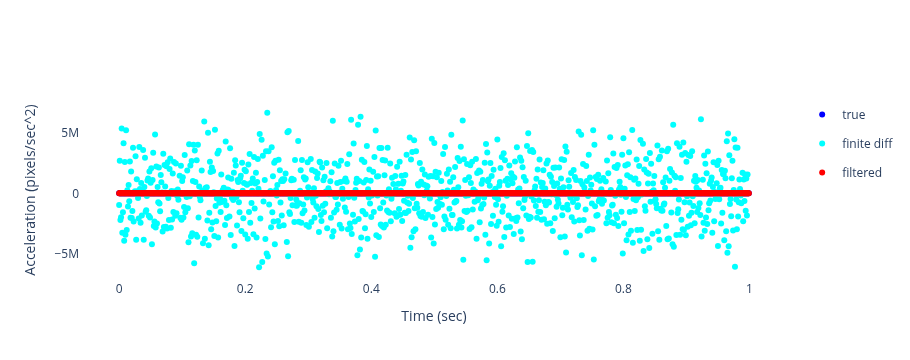

In [11]:
true_x = x[2, :]
other_x = acc_est_fd
other_label = "finite diff"
color_other = "cyan"
filter_mean_x = filtered_means[2, 0, :]

filter_ci_acc_upper = filter_mean_x + 1.96*filter_stds[:, 2]
filter_ci_acc_lower = filter_mean_x - 1.96*filter_stds[:, 2]

fig = get_fig_kinematics_vs_time(
    time=time,
    true_x=true_x,
    other_x=other_x,
    filtered_mean_x=filter_mean_x,
    filtered_ci_x_upper=filter_ci_acc_upper,
    filtered_ci_x_lower=filter_ci_acc_lower,
    cb_alpha=cb_alpha,
    color_true=color_true,
    color_filtered_pattern=color_filtered_pattern,
    color_other=color_other,
    xlabel="Time (sec)", ylabel="Acceleration (pixels/sec^2)",
    other_label=other_label)
fig